# What is a backup payment option worth? An event study of card outages

**Research question:** how much revenue do stores lose when card payments fail, and how much of it does a backup payment option (account-to-account/QR at the till) retain?

This notebook is the **method and data plan** for a master's thesis proposal. It does not need any company's transaction data. It follows the three work packages of the proposal:

| Work package | Data | In this repository |
|---|---|---|
| WP1 Public evidence | Riksbank statistics, public outage reports | `templates/outage_catalogue_template.csv` |
| WP2 Merchant survey and interviews | Survey answers | `survey/questionnaire.md`, `survey/analysis.py` (section 8) |
| WP3 Calibrated simulation and cost-benefit | Synthetic data built from WP1 and WP2 | `simulate.py`, `analysis.py`, `config/assumptions.json` |

Simulated data is used because its **true effects are known**, so we can check that the method recovers them. If a retailer later shares aggregated, anonymised data, the same code runs on it.

**Background:** Mäder, Meyer, Nacht & Gatica-Perez (2026, SNB WP 2026-12) show that consumers fell back on **cash** during a Swiss card outage. Sweden has little cash left, so the question is whether **digital** fallbacks can take that role. The Riksbank has pushed for offline card payments for essential goods from 1 July 2026.

## 1. Assumptions
Every number the simulation uses sits in one file, `config/assumptions.json`, with a note on where the real value will come from.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import analysis as an
import simulate

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_colwidth", 110)
IMG = Path("images"); IMG.mkdir(exist_ok=True)

cfg = simulate.load_config()
pd.Series(cfg["calibration"], name="where the real value comes from").to_frame()

,where the real value comes from
payment_mix,WP1: Riksbank payment reports and surveys; WP2: survey Q5
outages,"WP1: outage catalogue from public sources (templates/outage_catalogue_template.csv): frequency, duration, ..."
switching_during_outage,WP2: survey questions Q8-Q10 and interviews (what customers did when cards failed)
catch_up_share,WP2: survey question Q11 (did customers come back later?)
backup.share_of_stores,WP2: survey question Q12 (which fallbacks merchants have)
backup.selection_on_size,WP2: survey (are larger merchants more likely to have a backup?); > 0 = bigger stores more likely
base_sales_sek_per_hour,WP2: survey question Q3 (store size band); public retail statistics
economics.gross_margin,Public: annual reports of listed Nordic retailers; WP2 interviews
economics.backup_cost_sek_per_store_year,Supplier price lists (e.g. ID24's Resilient Payments); compared with willingness to pay in survey Q14


In [2]:
# The effects built into the simulation (what a correct method must recover)
truth = simulate.true_effects(cfg)
truth

{'loss_without_backup': -0.559, 'retained_by_backup': 0.30100000000000005}

## 2. Simulated data

In [3]:
df, stores, outages = simulate.simulate(cfg)
print(f"{len(df):,} store-hours | {len(stores)} stores | {stores.has_backup.mean():.0%} with backup | "
      f"{len(outages)} outages")
outages

262,800 store-hours | 60 stores | 50% with backup | 5 outages


,event,date,start_hour,hours,scope
0,1,2025-03-14,11,3,National
1,2,2025-05-22,16,2,North
2,3,2025-08-29,12,4,National
3,4,2025-10-10,17,2,South
4,5,2025-11-28,13,3,National


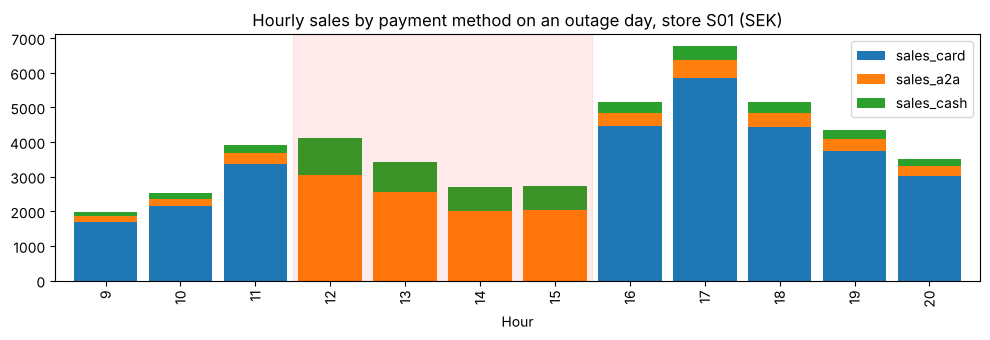

In [4]:
# One store on the day of the national outage of 29 August (12:00-16:00)
store = df.loc[df.event == 3, "store_id"].iloc[0]
day = df[(df.store_id == store) & (df.date == "2025-08-29")]
ax = day.set_index("hour")[["sales_card", "sales_a2a", "sales_cash"]].plot.bar(
    stacked=True, figsize=(10, 3.5), width=0.85)
ax.set_title(f"Hourly sales by payment method on an outage day, store {store} (SEK)")
ax.set_xlabel("Hour"); ax.axvspan(2.5, 6.5, color="red", alpha=0.08)
plt.tight_layout(); plt.show()

## 3. Counterfactual sales

What would sales have been **without** the outage? A fixed-effects model of log sales, estimated on normal hours only (not during an outage, not in the two hours after):

```latex
\log(\text{sales}_{s,d,h}) = \alpha_s + \delta_d + \gamma_{w(d),h} + \varepsilon_{s,d,h}
```

- α: store size; δ: the day (paydays, Black Friday); γ: weekday × hour pattern
- The day effect is identified from **unaffected** stores and hours on the same day, which act as a control group
- Estimated by alternating projections (the idea behind Stata's `reghdfe`)

**residual = actual / counterfactual − 1**

In [5]:
df, model = an.add_counterfactual(df)
normal = df[~df.disturbed]
print(f"Normal hours: residual std = {normal.residual.std():.3f}, mean = {normal.residual.mean():+.4f}")

Normal hours: residual std = 0.159, mean = +0.0000


## 4. Event study

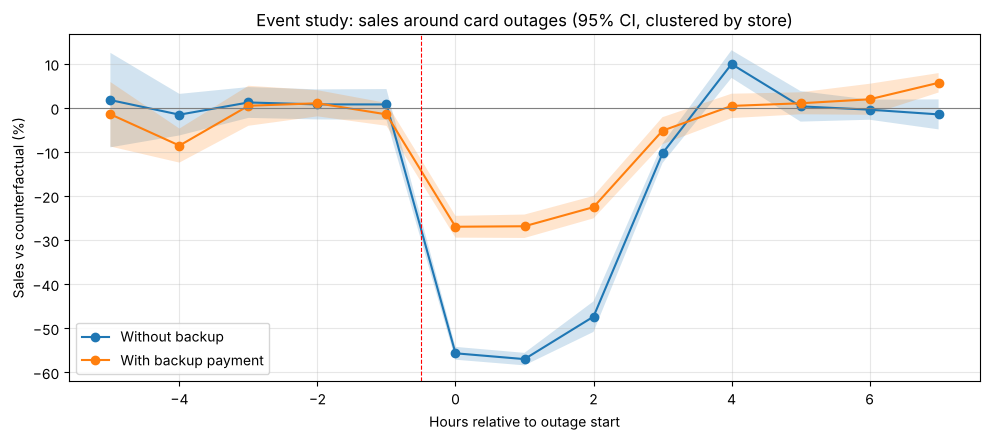

In [6]:
es = an.event_study(df)
fig, ax = plt.subplots(figsize=(10, 4.5))
for backup, g in es.groupby("has_backup"):
    label = "With backup payment" if backup else "Without backup"
    ax.plot(g.rel_hour, g["mean"] * 100, marker="o", label=label)
    ax.fill_between(g.rel_hour, g.lo * 100, g.hi * 100, alpha=0.2)
ax.axhline(0, color="grey", linewidth=0.8); ax.axvline(-0.5, color="red", linestyle="--", linewidth=0.8)
ax.set_xlabel("Hours relative to outage start"); ax.set_ylabel("Sales vs counterfactual (%)")
ax.set_title("Event study: sales around card outages (95% CI, clustered by store)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(IMG / "event_study.png", dpi=120); plt.show()

Before the outage both groups are at zero: **no pre-trend**, a key check for the design. Outages last 2–4 hours, so hours 2–3 mix outage and recovery; the small bump afterwards is delayed purchases.

## 5. Difference-in-differences

In [7]:
fit = an.did_regression(df)
print(fit.summary().tables[1])

ci = fit.conf_int()
pd.DataFrame({
    "true value": [truth["loss_without_backup"], truth["retained_by_backup"]],
    "estimate": [fit.params["outage"], fit.params["outage:backup"]],
    "95% CI": [f"[{ci.loc['outage', 0]:.3f}, {ci.loc['outage', 1]:.3f}]",
               f"[{ci.loc['outage:backup', 0]:.3f}, {ci.loc['outage:backup', 1]:.3f}]"],
}, index=["Sales change during outage, no backup", "Extra share of sales kept with backup"])

                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -0.0004      0.006     -0.070      0.944      -0.012       0.012
outage           -0.5645      0.009    -65.247      0.000      -0.581      -0.548
backup            0.0023      0.008      0.298      0.766      -0.013       0.017
outage:backup     0.3005      0.013     23.570      0.000       0.275       0.325
after             0.0960      0.011      8.748      0.000       0.075       0.118
after:backup     -0.0744      0.017     -4.362      0.000      -0.108      -0.041


,true value,estimate,95% CI
"Sales change during outage, no backup",-0.559,-0.564,"[-0.581, -0.548]"
Extra share of sales kept with backup,0.301,0.300,"[0.275, 0.325]"


The estimates are close to the true values and their confidence intervals include them: the method works where the answer is known.

### Placebo test: fake outage dates
A good design should find **nothing** when nothing happened. Each outage is moved 7, 14 or 21 days earlier or later (same weekday, hours and stores) and the same regression is run again. The backup effect b3 should be close to zero, with confidence intervals that include zero.

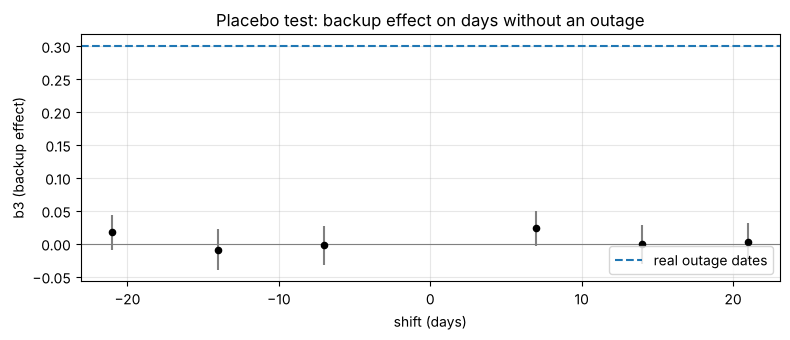

,shift (days),b3,se,lo,hi,p-value
0,-21,0.017,0.014,-0.009,0.044,0.201
1,-14,-0.009,0.016,-0.040,0.022,0.563
2,-7,-0.003,0.015,-0.032,0.027,0.868
3,7,0.023,0.014,-0.003,0.050,0.087
4,14,-0.001,0.015,-0.031,0.028,0.936
5,21,0.002,0.015,-0.027,0.032,0.876


In [8]:
placebo = an.placebo_did(df, outages)
ax = placebo.plot(x="shift (days)", y="b3", kind="scatter", figsize=(8, 3.5), color="black", zorder=3)
ax.errorbar(placebo["shift (days)"], placebo["b3"], yerr=1.96 * placebo["se"], fmt="none", color="grey")
ax.axhline(0, color="grey", linewidth=0.8)
ax.axhline(fit.params["outage:backup"], color="tab:blue", linestyle="--", label="real outage dates")
ax.set_ylabel("b3 (backup effect)"); ax.set_title("Placebo test: backup effect on days without an outage")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.savefig(IMG / "placebo.png", dpi=120); plt.show()
placebo.round(3)

All placebo estimates are close to zero and far from the real estimate: the effect is found only on real outage days.

## 6. Where did card customers go?

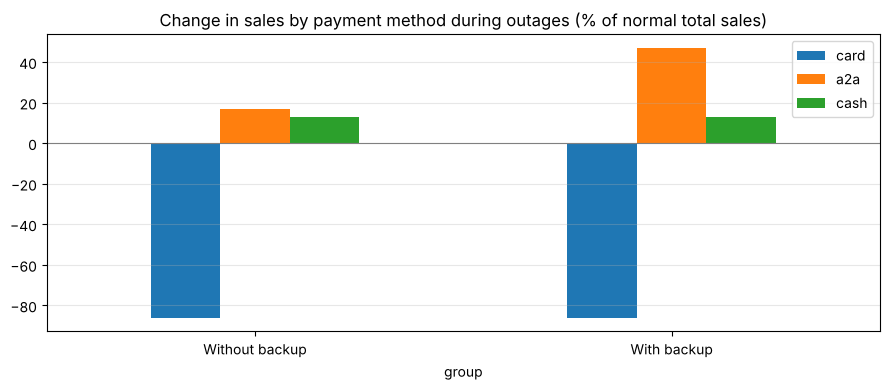

,card: change vs normal (% of normal total sales),a2a: change vs normal (% of normal total sales),cash: change vs normal (% of normal total sales),total change
group,,,,
Without backup,-0.860,0.169,0.127,-0.564
With backup,-0.860,0.470,0.128,-0.262


In [9]:
dec = an.method_decomposition(df)
ax = (dec.drop(columns="total change") * 100).rename(columns=lambda c: c.split(":")[0]).plot.bar(
    figsize=(9, 4), rot=0)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_title("Change in sales by payment method during outages (% of normal total sales)")
ax.grid(alpha=0.3, axis="y"); plt.tight_layout(); plt.savefig(IMG / "method_shift.png", dpi=120); plt.show()
dec

## 7. Robustness: what if bigger stores are more likely to have a backup?

In reality, stores choose whether to have a backup, and bigger chains may be more likely to. A **naive comparison** of sales during outages (backup stores vs others) then mixes the effect of the backup with store size. The design above compares each store with its **own** counterfactual, so store size drops out.

In [10]:
rows = []
for selection in [0.0, 1.5]:
    c = simulate.load_config(backup={"share_of_stores": 0.5, "selection_on_size": selection})
    d, s, _ = simulate.simulate(c)
    d, _ = an.add_counterfactual(d)
    f = an.did_regression(d)
    rows.append({"bigger stores more likely to have backup": "no" if selection == 0 else "yes (strongly)",
                 "true effect": simulate.true_effects(c)["retained_by_backup"],
                 "DiD estimate": f.params["outage:backup"],
                 "naive comparison of outage sales": an.naive_comparison(d)})
pd.DataFrame(rows).set_index("bigger stores more likely to have backup")

,true effect,DiD estimate,naive comparison of outage sales
bigger stores more likely to have backup,,,
no,0.301,0.300,1.066
yes (strongly),0.301,0.305,1.545


The naive comparison is far off and gets worse with selection. The difference-in-differences estimate stays close to the true value. With real data, selection on things that **change over time** would still be a threat; the thesis would check pre-trends and, where possible, use the date a backup was introduced.

## 8. Data requirements: how many stores and outages are enough?

A Monte Carlo study (`power.py`): many small simulated datasets, each with a given number of stores and outages. The **minimum detectable effect** (MDE) is the smallest backup effect the design would find with 80% power at the 5% level (2.8 × standard error).

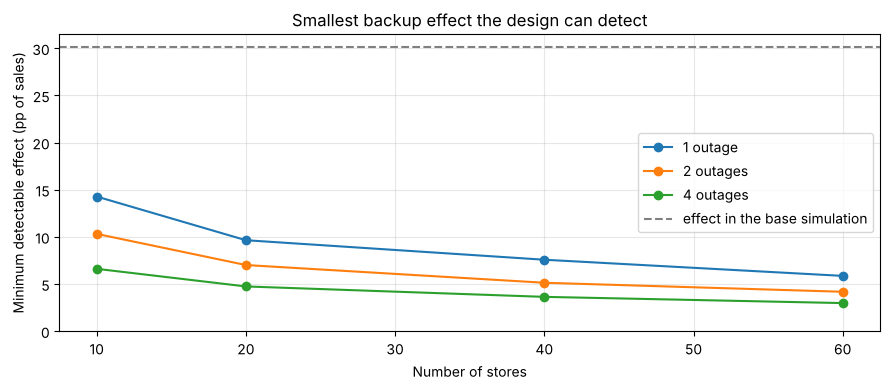

outages,1,2,4
stores,,,
10,14.300,10.300,6.600
20,9.600,7.000,4.700
40,7.600,5.100,3.600
60,5.900,4.200,3.000


In [11]:
power_file = simulate.DATA / "power_results.csv"
if power_file.exists():
    power = pd.read_csv(power_file)
else:
    import power as pw                       # about 2 minutes with 20 repetitions
    power = pw.power_study(reps=20)
    power.to_csv(power_file, index=False)

fig, ax = plt.subplots(figsize=(9, 4))
for n_o, g in power.groupby("outages"):
    ax.plot(g.stores, g.mde * 100, marker="o", label=f"{n_o} outage{'s' if n_o > 1 else ''}")
ax.axhline(truth["retained_by_backup"] * 100, color="grey", linestyle="--",
           label="effect in the base simulation")
ax.set_xlabel("Number of stores"); ax.set_ylabel("Minimum detectable effect (pp of sales)")
ax.set_title("Smallest backup effect the design can detect"); ax.legend(); ax.grid(alpha=0.3)
ax.set_ylim(0, None); plt.tight_layout(); plt.savefig(IMG / "power.png", dpi=120); plt.show()
power.pivot(index="stores", columns="outages", values="mde").rename_axis(columns="outages").mul(100).round(1)

**Reading it:** with 20 stores and one outage, effects smaller than about 10 percentage points could be missed; with 40 stores and two outages the limit is about 5 points. The estimates are unbiased at every size. This tells a data provider exactly how much aggregated data is enough, and the survey design can be sized the same way.

## 9. From survey answers to model inputs (work package 2)

`survey/analysis.py` turns survey answers into the assumptions above. Until real answers exist, it runs on **synthetic** responses with the same columns, so the whole pipeline is ready on day one.

In [12]:
from survey import analysis as sv

responses = sv.synthetic_responses(n=150)       # SYNTHETIC test answers, not real data
sv.describe(responses).to_frame("synthetic survey")

,synthetic survey
respondents,150.000
had at least one outage (24 months),0.747
have Swish/QR backup,0.233
have offline card payments,0.153
"customers switching, with backup",0.611
"customers switching, without backup",0.251
median willingness to pay (SEK/store/year),"1,000.000"


In [13]:
# What explains having a Swish/QR backup? Logit with robust standard errors.
logit_fit, ame = sv.adoption_logit(responses)
ame[["dy/dx", "Std. Err.", "Pr(>|z|)"]].rename(columns={"dy/dx": "average marginal effect"})

,average marginal effect,Std. Err.,Pr(>|z|)
C(sector)[T.Fashion],0.036,0.127,0.774
C(sector)[T.Grocery],0.066,0.119,0.582
C(sector)[T.Hotel],0.024,0.145,0.867
C(sector)[T.Other],0.139,0.149,0.349
C(sector)[T.Pharmacy],0.044,0.176,0.801
C(sector)[T.Restaurant],0.053,0.115,0.644
size_band,0.020,0.034,0.556
stores_band,0.104,0.029,0.000
outages_band,0.050,0.033,0.133


In [14]:
# Calibrate the model from the answers, simulate again and re-estimate
updates = sv.calibrate(responses)
cal_cfg = simulate.load_config(**updates)
d, _, _ = simulate.simulate(cal_cfg)
d, _ = an.add_counterfactual(d)
f = an.did_regression(d)
pd.DataFrame({"calibrated assumption": pd.Series({
    "card share": updates["payment_mix"]["card"],
    "switching without backup": sum(updates["switching_during_outage"]["without_backup"].values()),
    "switching with backup": sum(updates["switching_during_outage"]["with_backup"].values()),
    "share of stores with backup": updates["backup"]["share_of_stores"],
    "true effect of backup": simulate.true_effects(cal_cfg)["retained_by_backup"],
    "estimated effect of backup": f.params["outage:backup"]})})

,calibrated assumption
card share,0.839
switching without backup,0.250
switching with backup,0.611
share of stores with backup,0.233
true effect of backup,0.303
estimated effect of backup,0.304


## 10. The economics: is a backup worth paying for?

A backup works like **insurance**: a fixed yearly cost, paid back only when an outage happens.

```latex
V = b_3 \times \bar{S} \times H \times m
```

b3 = share of sales kept thanks to the backup, S̄ = normal sales per outage hour, H = outage hours per year, m = gross margin. Lost *sales* are not lost *profit*, so we multiply by the margin.

In [15]:
value = an.value_of_backup(df, fit, cfg)
pd.Series(value).to_frame("base simulation")

,base simulation
outage hours per store-year,10.933
normal sales per outage hour (SEK),"5,383.474"
share retained by backup (b3),0.300
value per store-year (SEK gross profit),"5,305.613"
assumed cost per store-year (SEK),"6,000.000"
break-even outage hours per year,12.364


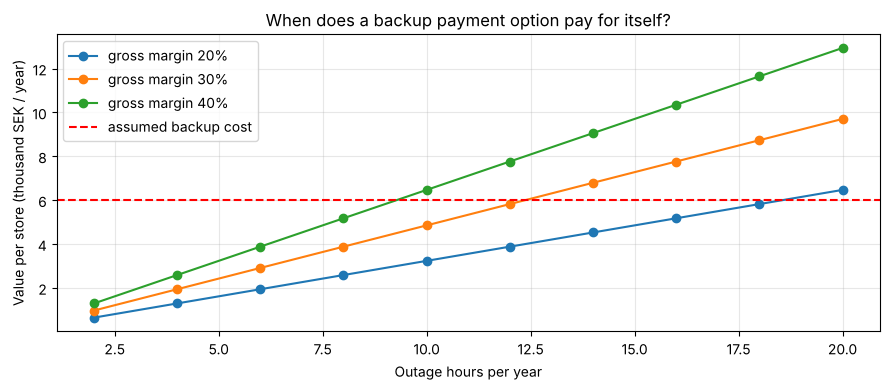

In [16]:
b3, s_bar = value["share retained by backup (b3)"], value["normal sales per outage hour (SEK)"]
cost = cfg["economics"]["backup_cost_sek_per_store_year"]
hours = np.arange(2, 21, 2)
fig, ax = plt.subplots(figsize=(9, 4))
for m in [0.2, 0.3, 0.4]:
    ax.plot(hours, b3 * s_bar * hours * m / 1000, marker="o", label=f"gross margin {m:.0%}")
ax.axhline(cost / 1000, color="red", linestyle="--", label="assumed backup cost")
ax.set_xlabel("Outage hours per year"); ax.set_ylabel("Value per store (thousand SEK / year)")
ax.set_title("When does a backup payment option pay for itself?"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(IMG / "break_even.png", dpi=120); plt.show()

The answer depends mostly on **how often outages happen**, which is why the public outage catalogue (WP1) matters as much as the survey.

## 11. Limitations and next steps
- Results here describe the method, not the world: every number comes from assumptions until WP1 and WP2 replace them.
- Real outages may also hit backup systems (e.g. a network failure); the outage catalogue records what was affected.
- Customers may go to a competitor instead; Mäder et al. find small effects at competing stores.
- Time-varying selection (stores adding a backup after a bad outage) needs pre-trend checks and adoption dates.

## References
- Mäder, A. R., Meyer, C., Nacht, Y. & Gatica-Perez, D. (2026). *Cash saves the day: How cash infrastructure enhances resilience during a card payment system outage.* SNB Working Paper 2026-12.
- Sveriges Riksbank (2025). *Offline card payments should be possible no later than 1 July 2026* (press release, 3 October 2025).
- Angrist, J. & Pischke, J.-S. (2009). *Mostly Harmless Econometrics.* Princeton University Press.

*All data in this notebook is simulated.*